<a href="https://colab.research.google.com/github/muhamadzakiabdulkhair-del/Kelompok-6-Bike-sharing/blob/main/EDA_Tahap1_KELOMPOK_6_BikeSharing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 1 Proyek Akhir Pembelajaran Mesin (INF62325): Eksplorasi Data
**Paket 5B-6: Bike Sharing (hour.csv)** | Kelas 5B | Kelompok 6
Anggota: Fadheel Abdilah Husen, Muhammad Zaki Abdul Khair

**Metode kelompok: Regresi Linear** (target `cnt`).

**Cara pakai:** upload `hour.csv` (dari arsip UCI) ke sesi Colab, lalu *Run all*.

## Langkah 0. Baca sumber dulu
Sumber: UCI Machine Learning Repository, *Bike Sharing Dataset* (Fanaee-T & Gama, 2013) + `Readme.txt` di arsip.

1. **Satu baris = apa?** Satu **jam** operasional sistem sepeda sewa Capital Bikeshare, Washington D.C. Isinya jumlah penyewaan pada jam itu beserta cuaca dan kalender.
2. **Arti kolom & satuan:** lihat Kamus Data di akhir notebook. Suhu, suhu terasa, kelembapan, dan kecepatan angin sudah **dinormalkan** (dibagi 41, 50, 100, 67).
3. **Kolom berisi kode:** `season`, `mnth`, `hr`, `weekday`, `weathersit` (kode kategori walau bertipe angka). `yr` 0 = 2011, 1 = 2012. `holiday` dan `workingday` bernilai 0/1.
4. **Cara & waktu pengumpulan:** log penyewaan dua tahun (2011-2012) dari Capital Bikeshare, digabung dengan data cuaca dari freemeteo.com dan kalender libur dari situs pemerintah D.C. Bukan data sintetis.
5. **Yang tidak ada:** data jam tanpa penyewaan (lihat temuan jam hilang di Langkah 3), lokasi stasiun, data peristiwa khusus, dan data tahun lain.

## Langkah 1. Muat data dengan benar

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
plt.rcParams['figure.dpi'] = 100

NAMA_BERKAS = 'hour.csv'          # bukan day.csv
df = pd.read_csv(NAMA_BERKAS)     # pemisah koma, UTF-8, tidak ada penanda hilang khusus
print('Berkas  :', NAMA_BERKAS)
print('Bentuk  :', df.shape, '(target di tabel paket: 17.379 baris x 17 kolom)')
assert df.shape == (17379, 17)
kolom_asli = list(df.columns)     # 17 kolom asli (kolom bantu ditambah kemudian)

Berkas  : hour.csv
Bentuk  : (17379, 17) (target di tabel paket: 17.379 baris x 17 kolom)


**Checklist Langkah 1:** bentuk 17.379 x 17 sesuai tabel paket; kolom lebih dari satu (pemisah koma benar); berkas `hour.csv` dicatat; tidak ada penanda hilang berbentuk teks (`?`, `unknown`) karena semua kolom numerik kecuali `dteday`.

## Langkah 2. Potret struktur dan unit analisis

In [3]:
display(df.head(10))
df.info()
display(df.describe().T.round(3))

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000,5017.029,1.00,4345.500,8690.000,13034.500,17379.000
season,17379.0,2.502,1.107,1.00,2.000,3.000,3.000,4.000
yr,17379.0,0.503,0.500,0.00,0.000,1.000,1.000,1.000
mnth,17379.0,6.538,3.439,1.00,4.000,7.000,10.000,12.000
hr,17379.0,11.547,6.914,0.00,6.000,12.000,18.000,23.000
holiday,17379.0,0.029,0.167,0.00,0.000,0.000,0.000,1.000
weekday,17379.0,3.004,2.006,0.00,1.000,3.000,5.000,6.000
workingday,17379.0,0.683,0.465,0.00,0.000,1.000,1.000,1.000
weathersit,17379.0,1.425,0.639,1.00,1.000,1.000,2.000,4.000
temp,17379.0,0.497,0.193,0.02,0.340,0.500,0.660,1.000


**Unit analisis:** satu baris = **satu jam operasional** (tanggal `dteday` + jam `hr`), bukan satu penyewa dan bukan satu hari. Karena itu `cnt` adalah *jumlah* sewa dalam jam tersebut.

**Ketidaksesuaian tipe vs arti (temuan):**
- `season`, `mnth`, `hr`, `weekday`, `weathersit` bertipe `int64` padahal kode kategori.
- `holiday`, `workingday` bertipe `int64` padahal penanda 0/1.
- `dteday` bertipe teks padahal tanggal.
- `yr` bernilai 0/1 yang artinya 2011/2012.

In [4]:
df['dteday_dt'] = pd.to_datetime(df['dteday'])
print('Periode:', df['dteday_dt'].min().date(), 's.d.', df['dteday_dt'].max().date())
print('Jumlah hari berbeda:', df['dteday'].nunique())

Periode: 2011-01-01 s.d. 2012-12-31
Jumlah hari berbeda: 731


## Langkah 3. Pemeriksaan kebersihan data

### 3a. Nilai hilang (cara biasa)

In [5]:
hilang = pd.DataFrame({'jumlah': df[kolom_asli].isna().sum(), 'persen': (df[kolom_asli].isna().mean()*100).round(2)})
display(hilang.sort_values('persen', ascending=False))
print('Total sel kosong:', int(df[kolom_asli].isna().sum().sum()))

,jumlah,persen
instant,0,0.0
dteday,0,0.0
season,0,0.0
yr,0,0.0
mnth,0,0.0
hr,0,0.0
holiday,0,0.0
weekday,0,0.0
workingday,0,0.0
weathersit,0,0.0


Total sel kosong: 0


### 3b. Data hilang yang tersamar (yang paling sering terlewat)

In [6]:
print('Kolom yang secara fisik tidak mungkin nol:')
for k in ['temp', 'atemp', 'hum']:
    print(f'  {k:10s} -> {(df[k]==0).sum():5d} baris bernilai nol')
print('Kolom windspeed bernilai nol :', (df['windspeed']==0).sum(),
      f"baris ({(df['windspeed']==0).mean()*100:.1f}%)")

# hum = 0: kapan terjadinya?
h0 = df[df['hum']==0]
print('\nBaris hum=0 per tanggal:'); display(h0.groupby('dteday').size().to_frame('baris'))
print('Jumlah baris pada tanggal itu:', (df['dteday']=='2011-03-10').sum())

# windspeed: nilai terkecil yang bukan nol -> ada "celah" antara 0 dan nilai pertama?
ws = np.sort(df['windspeed'].unique())
print('\nNilai windspeed terkecil:', ws[:5])
print('Sebaran windspeed=0 per tahun (persen):')
print((df.groupby('yr')['windspeed'].apply(lambda s: (s==0).mean()*100)).round(1).to_dict())

Kolom yang secara fisik tidak mungkin nol:
  temp       ->     0 baris bernilai nol
  atemp      ->     2 baris bernilai nol
  hum        ->    22 baris bernilai nol
Kolom windspeed bernilai nol : 2180 baris (12.5%)

Baris hum=0 per tanggal:


,baris
dteday,
2011-03-10,22


Jumlah baris pada tanggal itu: 22

Nilai windspeed terkecil: [0.     0.0896 0.1045 0.1343 0.1642]
Sebaran windspeed=0 per tahun (persen):
{0: 12.8, 1: 12.3}


**Temuan:**
- `hum = 0` muncul di 22 baris, **semuanya pada satu hari yang sama (2011-03-10)**, dan seluruh baris hari itu (22 dari 22) bernilai 0. Kelembapan 0 persen tidak mungkin untuk kota seperti D.C., jadi ini kerusakan sensor/pencatatan, bukan cuaca nyata.
- `windspeed = 0` ada di 2.180 baris (sekitar 12,5%), tersebar merata di kedua tahun. Nilai terkecil setelah nol adalah 0,0896 (sekitar 6 dari skala 67), jadi ada celah: angin pelan kemungkinan tercatat 0 (di bawah ambang alat) atau data tidak terukur. Tidak bisa dipastikan dari data; dicatat sebagai keterbatasan.
- Kolom `temp` tidak punya nol. `atemp` punya 2 nol (masih mungkin untuk suhu terasa yang dinormalkan, dicatat saja).

### 3b-2. Jam yang tidak tercatat (jam hilang secara implisit)

In [7]:
df['waktu'] = df['dteday_dt'] + pd.to_timedelta(df['hr'], unit='h')
lengkap = pd.date_range(df['waktu'].min(), df['waktu'].max(), freq='h')
print('Jam yang seharusnya ada :', len(lengkap))
print('Jam yang ada di berkas  :', len(df))
print('Jam yang tidak tercatat :', len(lengkap) - len(df))
print('Urut waktu?             :', df['waktu'].is_monotonic_increasing)
print('Nilai cnt terkecil      :', df['cnt'].min(), '(tidak ada jam bernilai 0)')
print('Hari dengan baris kurang dari 24 (5 teratas):')
print(df.groupby('dteday').size().loc[lambda s: s<24].sort_values().head(5).to_dict())

Jam yang seharusnya ada : 17544
Jam yang ada di berkas  : 17379
Jam yang tidak tercatat : 165
Urut waktu?             : True
Nilai cnt terkecil      : 1 (tidak ada jam bernilai 0)
Hari dengan baris kurang dari 24 (5 teratas):
{'2012-10-29': 1, '2011-01-27': 8, '2012-10-30': 11, '2011-01-18': 12, '2011-01-26': 16}


**Temuan:** ada 165 jam yang tidak muncul di berkas dan `cnt` minimum adalah 1. Artinya jam tanpa satu pun penyewaan **tidak dicatat** (bukan dicatat sebagai 0). Konsekuensi: sebaran `cnt` terpotong di bawah (tidak ada nol), terutama untuk dini hari. Ini keterbatasan data, bukan nilai hilang yang perlu diisi.

### 3c. Duplikat

In [8]:
print('Baris identik seluruhnya :', df.duplicated(subset=kolom_asli).sum())
print('instant berulang         :', df['instant'].duplicated().sum())
print('Pasangan (dteday, hr) berulang:', df.duplicated(subset=['dteday','hr']).sum())

Baris identik seluruhnya : 0
instant berulang         : 0
Pasangan (dteday, hr) berulang: 0


**Temuan:** tidak ada baris identik, tidak ada `instant` berulang, dan setiap pasangan (tanggal, jam) unik, jadi unit analisis "satu jam" konsisten.

### 3d. Kolom konstan dan identifier

In [9]:
n = df[kolom_asli].nunique()
print('Kolom konstan          :', list(n[n<=1].index))
print('Hampir unik per baris  :', list(n[n>0.9*len(df)].index))
display(n.to_frame('nilai_unik').T)

Kolom konstan          : []
Hampir unik per baris  : ['instant']


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
nilai_unik,17379,731,4,2,12,24,2,7,2,4,50,65,89,30,322,776,869


**Temuan:** tidak ada kolom konstan. `instant` (nomor urut, 17.379 nilai unik) adalah **identifier**, dibuang dari fitur.

### 3e. Nilai mustahil dan pencilan (per kolom)

In [10]:
def pagar(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5*i, q3 + 1.5*i
for k in ['cnt', 'casual', 'registered', 'hum', 'windspeed']:
    lo, hi = pagar(df[k]); n_out = ((df[k] < lo) | (df[k] > hi)).sum()
    print(f'{k:11s} min={df[k].min():7.3f} maks={df[k].max():7.3f}  di luar pagar IQR: {n_out:5d} ({n_out/len(df)*100:.1f}%)')
print()
print('Rentang normalisasi (harus 0..1):')
print(df[['temp','atemp','hum','windspeed']].agg(['min','max']).round(3))
print('\nKonsistensi kalender:')
dd = df['dteday_dt']
print('  weekday tidak cocok tanggal :', (((dd.dt.dayofweek+1) % 7) != df['weekday']).sum())
print('  yr tidak cocok tahun        :', ((dd.dt.year-2011) != df['yr']).sum())
print('  mnth tidak cocok bulan      :', (dd.dt.month != df['mnth']).sum())
libur_atau_akhirpekan = df['weekday'].isin([0,6]) | (df['holiday']==1)
print('  workingday salah rumus      :', (df['workingday'] != (~libur_atau_akhirpekan).astype(int)).sum())
print('  holiday=1 sekaligus workingday=1:', ((df['holiday']==1)&(df['workingday']==1)).sum())

cnt         min=  1.000 maks=977.000  di luar pagar IQR:   505 (2.9%)
casual      min=  0.000 maks=367.000  di luar pagar IQR:  1192 (6.9%)
registered  min=  0.000 maks=886.000  di luar pagar IQR:   680 (3.9%)
hum         min=  0.000 maks=  1.000  di luar pagar IQR:    22 (0.1%)
windspeed   min=  0.000 maks=  0.851  di luar pagar IQR:   342 (2.0%)

Rentang normalisasi (harus 0..1):
     temp  atemp  hum  windspeed
min  0.02    0.0  0.0      0.000
max  1.00    1.0  1.0      0.851

Konsistensi kalender:
  weekday tidak cocok tanggal : 0
  yr tidak cocok tahun        : 0
  mnth tidak cocok bulan      : 0
  workingday salah rumus      : 0
  holiday=1 sekaligus workingday=1: 0


**Temuan:** tidak ada nilai mustahil di luar kasus `hum = 0` (3b). Semua kolom normalisasi berada di rentang 0-1 dan kolom kalender konsisten dengan tanggal.
Pada `cnt`, sekitar 505 baris berada di luar pagar IQR, tetapi itu **pencilan nyata** (jam sibuk, cuaca bagus), bukan kesalahan. Maksimum `cnt` = 977 masuk akal untuk jam puncak. **Keputusan: tidak ada pencilan yang dibuang.**

### 3f. Konsistensi label kategori

In [11]:
for k in ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit']:
    print(f'{k:11s}', sorted(df[k].unique().tolist()))
print('\nSebaran weathersit:'); print(df['weathersit'].value_counts().sort_index())

season      [1, 2, 3, 4]
yr          [0, 1]
mnth        [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
hr          [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
holiday     [0, 1]
weekday     [0, 1, 2, 3, 4, 5, 6]
workingday  [0, 1]
weathersit  [1, 2, 3, 4]

Sebaran weathersit:
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


**Temuan:** tidak ada label ganda atau salah eja karena semuanya kode angka dengan nilai sesuai kamus. `weathersit = 4` hanya muncul di 3 baris dari 17.379 (diputuskan di Langkah 7).

### Grafik 1: sebaran variabel cuaca (menjawab: adakah nilai menumpuk atau mustahil?)

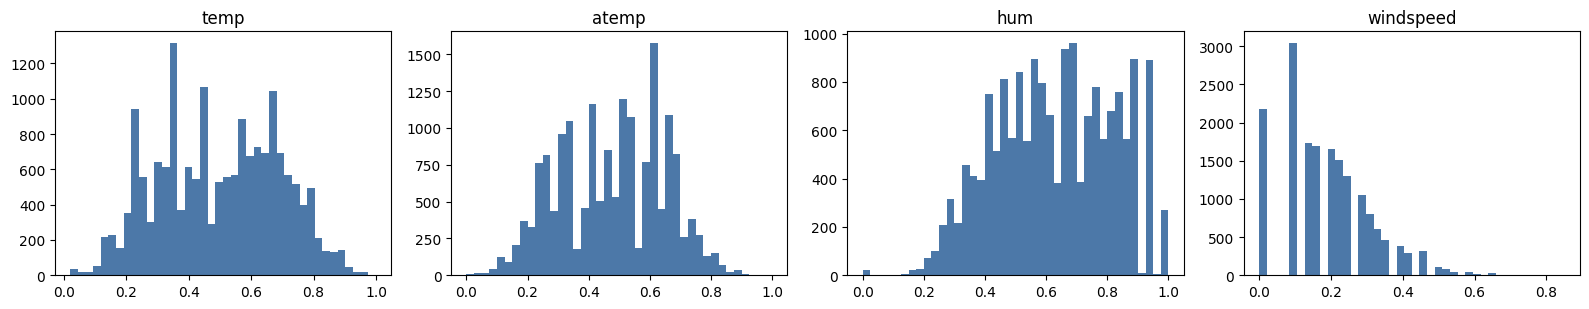

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, k in zip(ax, ['temp','atemp','hum','windspeed']):
    a.hist(df[k], bins=40, color='#4C78A8'); a.set_title(k)
plt.tight_layout(); plt.show()

**Penafsiran:** `hum` punya batang kecil di nilai 0 (sensor rusak 2011-03-10) dan tumpukan di 1,0 (kelembapan 100%, nyata). `windspeed` menumpuk di 0 lalu ada celah sebelum nilai berikutnya, ciri pembulatan/ambang alat. `temp` dan `atemp` bentuknya mirip, pertanda keduanya hampir sama.

## Langkah 4. Pahami variabel target (Regresi Linear, target `cnt`)

### Cabang A: Regresi Linear (target `cnt`)

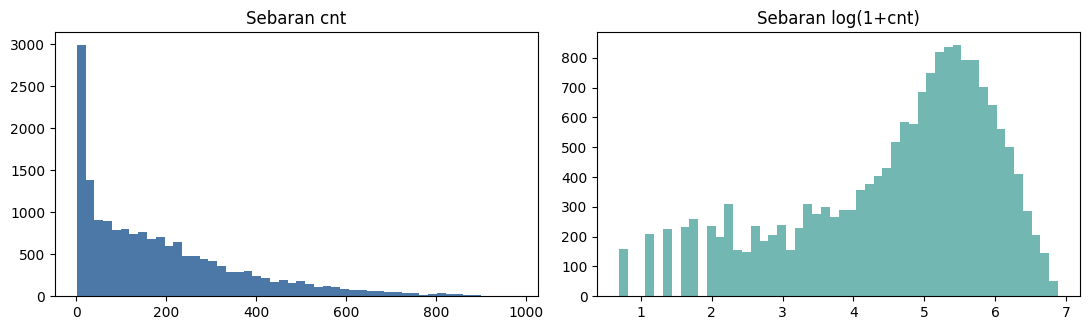

Skewness cnt: 1.277 | median 142.0 | rerata 189.5
Nilai berbeda pada cnt: 869 (bulat, berupa hitungan)
cnt = 0 : 0  cnt < 0 : 0


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df['cnt'], bins=50, color='#4C78A8'); ax[0].set_title('Sebaran cnt')
ax[1].hist(np.log1p(df['cnt']), bins=50, color='#72B7B2'); ax[1].set_title('Sebaran log(1+cnt)')
plt.tight_layout(); plt.show()
print('Skewness cnt:', round(df['cnt'].skew(), 3), '| median', df['cnt'].median(), '| rerata', round(df['cnt'].mean(),1))
print('Nilai berbeda pada cnt:', df['cnt'].nunique(), '(bulat, berupa hitungan)')
print('cnt = 0 :', (df['cnt']==0).sum(), ' cnt < 0 :', (df['cnt']<0).sum())

**Grafik 2 (penafsiran):** `cnt` menceng kuat ke kanan (skewness sekitar 1,28; median 142 jauh di bawah rerata 189). Banyak jam sepi, sedikit jam sangat ramai. Regresi linear cenderung keliru di ekor kanan. `cnt` berupa hitungan bulat dengan 869 nilai berbeda, jadi cukup kontinu untuk regresi. Tidak ada `cnt` nol atau negatif (lihat juga catatan jam hilang di 3b-2).

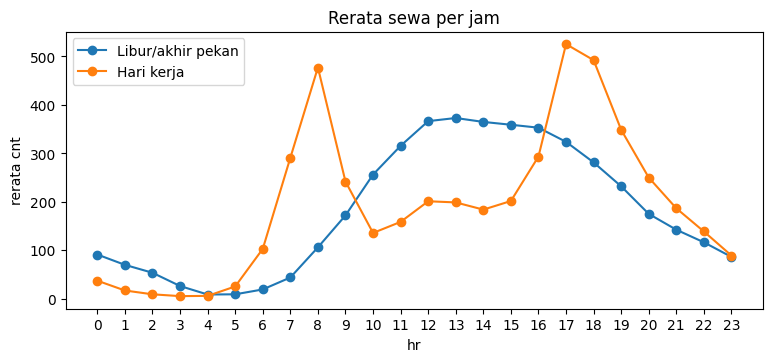

In [14]:
rata = df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
rata.columns = ['Libur/akhir pekan', 'Hari kerja']
rata.plot(figsize=(9, 3.6), marker='o'); plt.xticks(range(24)); plt.ylabel('rerata cnt'); plt.title('Rerata sewa per jam'); plt.show()

**Grafik 3 (penafsiran):** pada hari kerja ada **dua puncak** (sekitar jam 8 dan jam 17-18, jam berangkat dan pulang kerja), sedangkan akhir pekan satu puncak landai siang hari. Polanya melengkung dan berbeda menurut jenis hari, jadi `hr` tidak boleh dipakai sebagai angka lurus (jam 23 bukan "lebih besar" dari jam 2) dan hubungan `hr` dengan `workingday` bersifat interaksi.

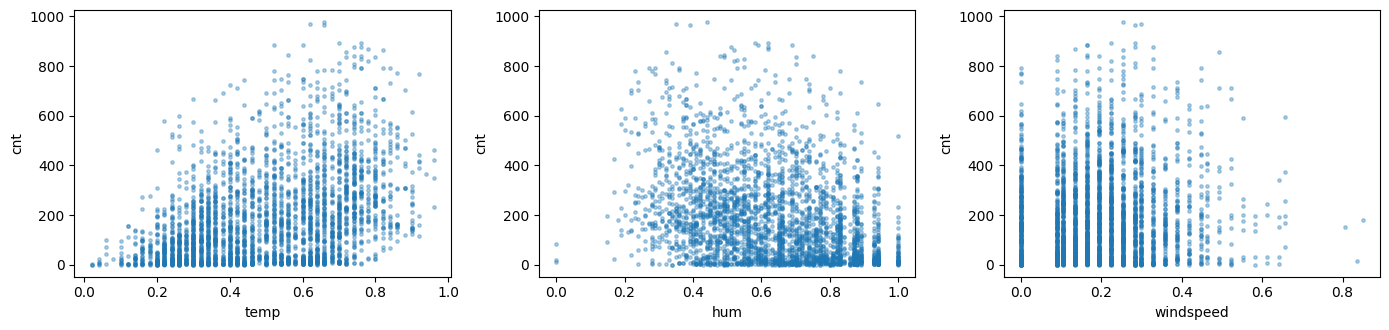

temp         0.405
atemp        0.401
hum         -0.323
windspeed    0.093
hr           0.394
dtype: float64


In [15]:
s = df.sample(3000, random_state=1)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, k in zip(ax, ['temp', 'hum', 'windspeed']):
    a.scatter(s[k], s['cnt'], s=6, alpha=.35); a.set_xlabel(k); a.set_ylabel('cnt')
plt.tight_layout(); plt.show()
print(df[['temp','atemp','hum','windspeed','hr']].corrwith(df['cnt']).round(3))

**Grafik 4 (penafsiran):** `cnt` naik bersama suhu (korelasi sekitar 0,40) dan turun saat kelembapan tinggi (sekitar -0,32). Angin hampir tidak berhubungan (sekitar 0,09). Sebarannya melebar di suhu tinggi, tanda ragam tidak konstan.

**Dugaan kami sebelum memodelkan:** fitur paling berpengaruh adalah `hr` (pola jam berangkat/pulang kerja), lalu `temp`, lalu `workingday`/`weekday`. `windspeed` diduga paling lemah. Dibandingkan dengan hasil sebenarnya di Tahap 2.

## Langkah 5. Hubungan antar variabel dan kebocoran data

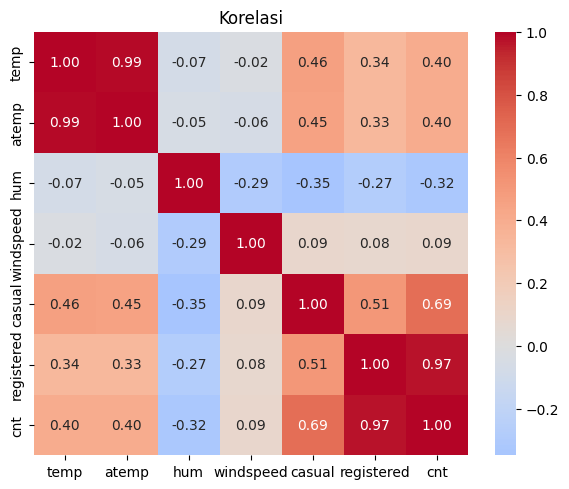

In [16]:
kor_kolom = ['temp','atemp','hum','windspeed','casual','registered','cnt']
kor = df[kor_kolom].corr()
plt.figure(figsize=(7, 5.5)); sns.heatmap(kor, annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Korelasi'); plt.show()

**Grafik 5 (penafsiran):** sel gelap di luar diagonal: `temp`-`atemp` (0,99, hampir kembar) dan `registered`-`cnt` (0,97) serta `casual`-`cnt` (0,69). Dua pasangan terakhir adalah tanda kebocoran, diperiksa di bawah.

In [17]:
# 1) Kebocoran definisional: cnt = casual + registered ?
selisih = (df['cnt'] - df['casual'] - df['registered']).abs()
print('Selisih maksimum |cnt - casual - registered| :', selisih.max())
print('Baris dengan selisih bukan nol              :', int((selisih>0).sum()))

# 2) Pemeriksaan cepat korelasi > 0,95 terhadap target cnt
k = df[['temp','atemp','hum','windspeed','casual','registered']].corrwith(df['cnt']).abs()
print('CURIGAI (korelasi > 0,95):', list(k[k>0.95].index))

# 3) Untuk target workingday: apakah ditentukan oleh weekday + holiday?
rumus = (~(df['weekday'].isin([0,6]) | (df['holiday']==1))).astype(int)
print('workingday salah dibanding rumus (weekday, holiday):', int((df['workingday']!=rumus).sum()), 'baris')

# 4) Multikolinearitas antarfitur (> 0,8)
fz = df[['temp','atemp','hum','windspeed']].corr().abs()
pasangan = [(a,b,round(fz.loc[a,b],3)) for i,a in enumerate(fz.columns) for b in fz.columns[i+1:] if fz.loc[a,b]>0.8]
print('Pasangan fitur berkorelasi > 0,8:', pasangan)

Selisih maksimum |cnt - casual - registered| : 0
Baris dengan selisih bukan nol              : 0
CURIGAI (korelasi > 0,95): ['registered']
workingday salah dibanding rumus (weekday, holiday): 0 baris
Pasangan fitur berkorelasi > 0,8: [('temp', 'atemp', np.float64(0.988))]


**Hasil pemeriksaan kebocoran (ditulis eksplisit):**
1. **`casual` + `registered` = `cnt` untuk seluruh baris** (selisih maksimum 0). Ini kebocoran **definisional** untuk regresi `cnt`. Keduanya dibuang dari fitur. Keduanya juga baru diketahui setelah jam berlalu (kebocoran waktu).
2. **`registered`** sendirian berkorelasi 0,97 dengan `cnt` (lampu merah, sesuai aturan >0,95).
3. **Multikolinearitas:** `temp` dan `atemp` berkorelasi 0,99. Pilih salah satu (diusulkan `temp`) agar koefisien regresi dapat ditafsirkan.
4. **Kesimpulan:** setelah `casual` dan `registered` dibuang, tidak ditemukan kebocoran lain. Fitur kalender dan cuaca sudah diketahui sebelum jam berlangsung.

### Perbandingan dua skenario (regresi `cnt`): dengan vs tanpa fitur bocor

In [18]:
dasar = ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit','temp','hum','windspeed']
def r2(fitur, kategori):
    X, y = df[fitur], df['cnt']
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    ct = ColumnTransformer([('k', OneHotEncoder(handle_unknown='ignore'), kategori)], remainder='passthrough')
    return make_pipeline(ct, LinearRegression()).fit(Xtr, ytr).score(Xte, yte)

hasil = pd.DataFrame({
    'skenario': ['A. dengan casual + registered (BOCOR)',
                 'B. tanpa keduanya, kode kategori dianggap angka',
                 'C. tanpa keduanya, kode kategori di-one-hot'],
    'R2 data uji': [r2(dasar+['casual','registered'], []),
                    r2(dasar, []),
                    r2(dasar, ['season','mnth','hr','weekday','weathersit'])]}).round(4)
display(hasil)

,skenario,R2 data uji
0,A. dengan casual + registered (BOCOR),1.000
1,"B. tanpa keduanya, kode kategori dianggap angka",0.386
2,"C. tanpa keduanya, kode kategori di-one-hot",0.681


**Penafsiran:** skenario A mendapat R² = **1,0000**, itu bukan prestasi, hanya akibat `cnt = casual + registered`. Skenario jujur (B) hanya sekitar **0,39**, dan memperlakukan `hr`, `mnth`, dll. sebagai kategori (C) menaikkannya jadi sekitar **0,68** tanpa menambah data, karena pola jam tidak lurus (Grafik 3). Perbandingan inilah yang dilaporkan, bukan angka yang paling tinggi. *(Pembagian acak dipakai hanya untuk demonstrasi ini; karena data runtun waktu, Tahap 2 sebaiknya membagi menurut waktu.)*

## Langkah 7. Keputusan praproses dan dataset bersih
**Keterbatasan yang perlu disebut:** data runtun waktu sehingga baris antar-jam tidak saling bebas; hanya dua tahun di satu kota; jam tanpa sewa tidak tercatat; `windspeed = 0` ambigu.

In [19]:
n0 = len(df)
df_bersih = df[kolom_asli].copy()

# 1) hum = 0 (sensor rusak, satu hari penuh)
n_hum0 = int((df_bersih['hum']==0).sum())
df_bersih = df_bersih[df_bersih['hum'] != 0]

# 2) weathersit 4 -> 3
n_w4 = int((df_bersih['weathersit']==4).sum())
df_bersih['weathersit'] = df_bersih['weathersit'].replace(4, 3)

# 3) buang casual, registered, instant
df_bersih = df_bersih.drop(columns=['casual', 'registered', 'instant']).reset_index(drop=True)

print('ukuran awal  :', df.shape[0], 'baris x', len(kolom_asli), 'kolom')
print('ukuran bersih:', df_bersih.shape)
print('baris dibuang:', n0 - len(df_bersih), '(hum=0:', n_hum0, ')  | baris digabung kelasnya (weathersit 4->3):', n_w4)
print('sisa NaN:', int(df_bersih.isna().sum().sum()))
df_bersih.to_csv('data_bersih.csv', index=False)

ukuran awal  : 17379 baris x 17 kolom
ukuran bersih: (17357, 14)
baris dibuang: 22 (hum=0: 22 )  | baris digabung kelasnya (weathersit 4->3): 3
sisa NaN: 0


### Tabel keputusan praproses

In [20]:
keputusan = pd.DataFrame([
 ['hum', '22 baris bernilai 0, semuanya tanggal 2011-03-10 (seluruh baris hari itu)', 'Baris dibuang', 'Kelembapan 0% mustahil; seluruh hari bernilai 0 = sensor rusak, tidak ada nilai pengganti yang aman', '22 dari 17.379 (0,13%)'],
 ['casual, registered', 'cnt = casual + registered untuk semua baris (selisih maks 0)', 'Kedua kolom dibuang', 'Kebocoran definisional (dan baru diketahui setelah jam berlalu)', '0 baris, 2 kolom'],
 ['instant', 'Nomor urut, 17.379 nilai unik', 'Dibuang', 'Identifier, tidak membawa informasi', '0 baris, 1 kolom'],
 ['weathersit', 'Kelas 4 hanya 3 baris', 'Digabung ke kelas 3', 'Terlalu sedikit untuk dipelajari/diuji; sama-sama cuaca buruk', '3 baris'],
 ['windspeed', '2.180 baris bernilai 0 (12,5%), ada celah sebelum nilai berikutnya', 'Dipertahankan, dicatat', 'Tidak dapat dipastikan salah ukur atau angin sangat pelan; membuang menghapus 1/8 data', '0 baris'],
 ['atemp', '2 baris bernilai 0', 'Dipertahankan, dicatat', 'Suhu terasa yang dinormalkan masih mungkin mendekati 0; hanya 2 baris dari 17.379', '0 baris'],
 ['cnt', 'Pencilan IQR sekitar 505 baris', 'Dipertahankan', 'Jam puncak nyata, bukan kesalahan', '0 baris'],
 ['jam hilang', '165 jam tidak tercatat (jam tanpa sewa)', 'Tidak diisi', 'Bukan nilai hilang acak; dicatat sebagai keterbatasan', '0 baris'],
 ['dteday', 'Bertipe teks padahal isinya tanggal', 'Diubah ke tanggal di notebook; di berkas bersih tetap teks YYYY-MM-DD', 'Format teks aman disimpan di CSV; diubah ke tanggal saat dibutuhkan (misalnya membagi data menurut waktu)', '0 baris'],
 ['temp, atemp', 'Korelasi 0,99', 'Dua-duanya disimpan di berkas bersih; pilih satu di Tahap 2', 'Multikolinearitas; koefisien regresi tak bisa ditafsirkan', '0 baris'],
 ['season, mnth, hr, weekday, weathersit', 'Kode kategori bertipe angka', 'Diperlakukan kategori saat memodelkan (one-hot)', 'Skenario C di Langkah 5 membuktikan bedanya', '0 baris'],
], columns=['Kolom / baris', 'Temuan', 'Keputusan', 'Alasan', 'Baris terpengaruh'])
pd.set_option('display.max_colwidth', None); display(keputusan)
keputusan.to_csv('tabel_keputusan.csv', index=False)

,Kolom / baris,Temuan,Keputusan,Alasan,Baris terpengaruh
0,hum,"22 baris bernilai 0, semuanya tanggal 2011-03-10 (seluruh baris hari itu)",Baris dibuang,"Kelembapan 0% mustahil; seluruh hari bernilai 0 = sensor rusak, tidak ada nilai pengganti yang aman","22 dari 17.379 (0,13%)"
1,"casual, registered",cnt = casual + registered untuk semua baris (selisih maks 0),Kedua kolom dibuang,Kebocoran definisional (dan baru diketahui setelah jam berlalu),"0 baris, 2 kolom"
2,instant,"Nomor urut, 17.379 nilai unik",Dibuang,"Identifier, tidak membawa informasi","0 baris, 1 kolom"
3,weathersit,Kelas 4 hanya 3 baris,Digabung ke kelas 3,Terlalu sedikit untuk dipelajari/diuji; sama-sama cuaca buruk,3 baris
4,windspeed,"2.180 baris bernilai 0 (12,5%), ada celah sebelum nilai berikutnya","Dipertahankan, dicatat",Tidak dapat dipastikan salah ukur atau angin sangat pelan; membuang menghapus 1/8 data,0 baris
5,atemp,2 baris bernilai 0,"Dipertahankan, dicatat",Suhu terasa yang dinormalkan masih mungkin mendekati 0; hanya 2 baris dari 17.379,0 baris
6,cnt,Pencilan IQR sekitar 505 baris,Dipertahankan,"Jam puncak nyata, bukan kesalahan",0 baris
7,jam hilang,165 jam tidak tercatat (jam tanpa sewa),Tidak diisi,Bukan nilai hilang acak; dicatat sebagai keterbatasan,0 baris
8,dteday,Bertipe teks padahal isinya tanggal,Diubah ke tanggal di notebook; di berkas bersih tetap teks YYYY-MM-DD,Format teks aman disimpan di CSV; diubah ke tanggal saat dibutuhkan (misalnya membagi data menurut waktu),0 baris
9,"temp, atemp","Korelasi 0,99",Dua-duanya disimpan di berkas bersih; pilih satu di Tahap 2,Multikolinearitas; koefisien regresi tak bisa ditafsirkan,0 baris


## Kamus data (Lampiran A)

In [21]:
kamus = pd.DataFrame([
 ['instant', 'Nomor urut catatan', '-', 'bulat', 'identifier', '17.379 nilai unik; dibuang dari data bersih'],
 ['dteday', 'Tanggal pencatatan', 'tanggal', 'tanggal (dari teks)', 'identifier', 'tidak ada nilai hilang; dipertahankan untuk membagi data menurut waktu, bukan sebagai fitur'],
 ['season', 'Musim: 1 semi, 2 panas, 3 gugur, 4 dingin', '-', 'kategori (dari kode angka)', 'fitur', 'batas musim mengikuti tanggal astronomis, bukan awal bulan'],
 ['yr', 'Tahun: 0 = 2011, 1 = 2012', '-', 'kategori biner', 'fitur', 'tidak ada nilai hilang'],
 ['mnth', 'Bulan, 1-12', 'bulan', 'kategori (dari kode angka)', 'fitur', 'cocok dengan dteday'],
 ['hr', 'Jam, 0-23', 'jam', 'kategori (melingkar)', 'fitur', 'jam 23 dekat jam 0'],
 ['holiday', 'Hari libur resmi (1) atau bukan (0)', '-', 'kategori biner', 'fitur', 'ikut menentukan workingday'],
 ['weekday', 'Hari dalam pekan, 0-6 (0 = Minggu)', '-', 'kategori (dari kode angka)', 'fitur', 'cocok dengan dteday'],
 ['workingday', '1 jika bukan akhir pekan dan bukan libur', '-', 'kategori biner', 'fitur', 'turunan dari weekday dan holiday; informasinya tumpang tindih'],
 ['weathersit', 'Cuaca: 1 cerah, 2 berkabut/berawan, 3 hujan/salju (kelas 4 digabung ke 3)', '-', 'kategori ordinal', 'fitur', 'kelas 4 hanya 3 baris, digabung ke kelas 3'],
 ['temp', 'Suhu', '0-1 (asli: derajat C, temp x 41)', 'numerik', 'fitur', 'berkorelasi 0,99 dengan atemp'],
 ['atemp', 'Suhu terasa', '0-1 (asli: derajat C, atemp x 50)', 'numerik', 'fitur', 'multikolinear dengan temp (pilih salah satu); 2 baris bernilai 0'],
 ['hum', 'Kelembapan', '0-1 (asli: persen, hum x 100)', 'numerik', 'fitur', '22 baris hum=0 (2011-03-10) dibuang'],
 ['windspeed', 'Kecepatan angin', '0-1 (asli: windspeed x 67)', 'numerik', 'fitur', '12,5% bernilai 0 (ambigu)'],
 ['casual', 'Jumlah sewa pengguna tak terdaftar', 'sepeda per jam', 'bulat', 'dibuang', 'penyusun cnt (bocor)'],
 ['registered', 'Jumlah sewa pengguna terdaftar', 'sepeda per jam', 'bulat', 'dibuang', 'penyusun cnt (bocor)'],
 ['cnt', 'Jumlah total sewa pada jam itu', 'sepeda per jam', 'bulat', 'target', 'menceng kanan; tidak ada nilai 0'],
], columns=['Nama kolom', 'Arti', 'Satuan', 'Tipe yang ditetapkan', 'Peran', 'Catatan mutu'])
display(kamus); kamus.to_csv('kamus_data.csv', index=False)

,Nama kolom,Arti,Satuan,Tipe yang ditetapkan,Peran,Catatan mutu
0,instant,Nomor urut catatan,-,bulat,identifier,17.379 nilai unik; dibuang dari data bersih
1,dteday,Tanggal pencatatan,tanggal,tanggal (dari teks),identifier,"tidak ada nilai hilang; dipertahankan untuk membagi data menurut waktu, bukan sebagai fitur"
2,season,"Musim: 1 semi, 2 panas, 3 gugur, 4 dingin",-,kategori (dari kode angka),fitur,"batas musim mengikuti tanggal astronomis, bukan awal bulan"
3,yr,"Tahun: 0 = 2011, 1 = 2012",-,kategori biner,fitur,tidak ada nilai hilang
4,mnth,"Bulan, 1-12",bulan,kategori (dari kode angka),fitur,cocok dengan dteday
5,hr,"Jam, 0-23",jam,kategori (melingkar),fitur,jam 23 dekat jam 0
6,holiday,Hari libur resmi (1) atau bukan (0),-,kategori biner,fitur,ikut menentukan workingday
7,weekday,"Hari dalam pekan, 0-6 (0 = Minggu)",-,kategori (dari kode angka),fitur,cocok dengan dteday
8,workingday,1 jika bukan akhir pekan dan bukan libur,-,kategori biner,fitur,turunan dari weekday dan holiday; informasinya tumpang tindih
9,weathersit,"Cuaca: 1 cerah, 2 berkabut/berawan, 3 hujan/salju (kelas 4 digabung ke 3)",-,kategori ordinal,fitur,"kelas 4 hanya 3 baris, digabung ke kelas 3"


*Satuan asli:* rumus pengembalian dari `Readme.txt` arsip UCI (suhu x 41, suhu terasa x 50, kelembapan x 100, angin x 67).

**Berkas keluaran Tahap 1:** `data_bersih.csv`, `kamus_data.csv`, `tabel_keputusan.csv`, dan notebook ini (dijalankan penuh tanpa kesalahan).